# Netting-set exposure and XVA

A counterparty's future exposure depends on the combined value of trades
covered by its netting agreement. We compare two offsetting swaps held in one
netting set with the same positions held in separate sets, then examine the
effect of variation margin on CVA and FVA.

The model configuration controls future SOFR dynamics and the exposure grid.
Each `NettingSet` carries `CsaTerms` specifying collateral, credit and funding
assumptions. Keeping those inputs equal across the comparison lets us examine
how grouping the trades changes exposure.
[Setup](../README.md) · [Portfolio PV and risk](../sensitivity/portfolio_risk.ipynb).


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import quantsupport as qs
from market_data import load_market, read_configuration

market = load_market()
ref = market.quotes.reference_date
config_spec = read_configuration("cva", "xva.json")
config = qs.XvaConfig.from_dict(config_spec)
config_spec


{'model_configs': [{'market_index': 'SOFR',
   'lambda': 0.05,
   'parameter_source': {'Calibrated': {'source': {'Surface': {'market_index': 'SOFR'}},
     'calibration_basket': {'expiries': ['3M', '6M', '1Y', '2Y', '3Y'],
      'strike': 'Atm'}}}}],
 'n_paths': 1024,
 'seed': 42,
 'frequency': 'Quarterly'}

## Model and agreement assumptions

The [configuration](data/xva.json) specifies a calibrated SOFR LGM model,
1,024 paths, seed 42 and quarterly exposure dates. Its ATM caplet basket uses
3M, 6M, 1Y, 2Y and 3Y expiries for the three-year portfolio. A longer horizon
would require reviewing the basket and its strike-domain coverage.

The [credit configuration](data/credit_curves.json) bootstraps CORPORATE-A
survival probabilities from illustrative CDS quotes at 1Y, 3Y and 5Y.
The CSA uses this credit index and 40% recovery. Funding spreads over SOFR
are supplied directly as a tenor curve with 40, 50 and 60 bp pillars.
The configured credit index takes precedence over the flat credit-spread
fallback.

Variation margin uses USD 1,000 thresholds in both directions and a USD 500
minimum transfer amount. Calls settle immediately at every simulation date,
including the initial date; retained balances accrue on SOFR. The model omits
settlement lag, margin period of risk and initial margin.

The two swaps have the same maturity and opposite directions, with different
notionals. Both hypothetical clients use identical credit and funding terms.


In [2]:
def swap(identifier, notional, side):
    instrument = qs.Swap(
        identifier=identifier,
        start_date=ref,
        maturity_date=ref + "3Y",
        notional=notional,
        fixed_rate=0.045,
        currency=qs.Currency.USD,
        market_index=qs.MarketIndex.SOFR,
    )
    return qs.Trade(instrument, ref, side)


receive = swap("RECEIVE", 1_000_000, qs.Side.LongReceive)
pay = swap("PAY", 800_000, qs.Side.PayShort)
funding_curve = qs.TenorBasedZeroRateTermStructure(
    reference_date=ref,
    tenors=["0D", "1Y", "3Y"],
    rates=[0.004, 0.005, 0.006],
    day_counter=qs.DayCounter.Actual365,
    compounding=qs.Compounding.Continuous,
    interpolator="Linear",
    enable_extrapolation=True,
)
csa = qs.CsaTerms(
    collateral_index=qs.MarketIndex.SOFR,
    collateral_currency=qs.Currency.USD,
    credit_index=qs.MarketIndex.credit("CORPORATE-A"),
    credit_spread=0.01,
    recovery=0.4,
    funding_spread_curve=funding_curve,
    counterparty_threshold=1_000.0,
    own_threshold=1_000.0,
    minimum_transfer_amount=500.0,
    variation_margin=True,
)


def run_exposure(netting_sets):
    with qs.PricingContext(
        quotes=market.quotes,
        curves=market.curves,
        credit_curves=market.credit_curves,
        csa_policy=market.csa_policy,
        volatility_surfaces=market.volatility_surfaces,
    ) as context:
        return context.run_xva(config, netting_sets=netting_sets)


netted = run_exposure([qs.NettingSet("ONE-CLIENT", [receive, pay], csa)])
separate = run_exposure(
    [qs.NettingSet("CLIENT-A", [receive], csa), qs.NettingSet("CLIENT-B", [pay], csa)]
)
netted.xva_values


,netting_set,measure,value
0,ONE-CLIENT,CVA,14.881481
1,ONE-CLIENT,FVA,3.382016


## Exposure and adjustment results

`xva_values` reports each netting set's adjustments. Exposure profiles are
selected by `netting_set`, so the analysis is independent of list order.
They contain pointwise positive, negative and signed mean values, with
`EE = EPE + ENE` and signed nonpositive ENE.

These profiles are raw values before margin. CVA and FVA instead consume
path values after variation margin, so the margin setting can change
adjustments while leaving the returned profiles unchanged. Python exposes
these summaries rather than pathwise cubes or PFE percentiles.

The sensitivity table requires separate units. Credit factories create
independent survival-probability leaves: `CVA.Cds_...` rows measure
$\partial XVA/\partial S(t_j)$ even when their labels resemble CDS quotes.
The credit bootstrap Jacobian is omitted from that path. Here funding pillars
are supplied directly as annual decimal spreads; a curve-driven factory would
create derived spread leaves.


In [3]:
netted_profiles = {
    profile.netting_set: profile.to_dataframe().set_index("date")
    for profile in netted.exposures
}
separate_profiles = {
    profile.netting_set: profile.to_dataframe().set_index("date")
    for profile in separate.exposures
}
profile = netted_profiles["ONE-CLIENT"]
separate_total = separate_profiles["CLIENT-A"] + separate_profiles["CLIENT-B"]
profile.head(8)


,epe,ene,ee
date,,,
2026-02-24,1568.045205,0.000000,1568.045205
2026-02-26,1570.102518,-1.675792,1568.426726
2026-05-26,2709.472528,-1132.070517,1577.402011
2026-08-26,3179.604030,-1328.045498,1851.558532
2026-11-26,3677.702323,-1836.833903,1840.868421
2027-02-26,3600.592786,-1481.521548,2119.071238
2027-05-26,3846.197149,-1744.215467,2101.981682
2027-08-26,3157.940941,-1344.778352,1813.162588


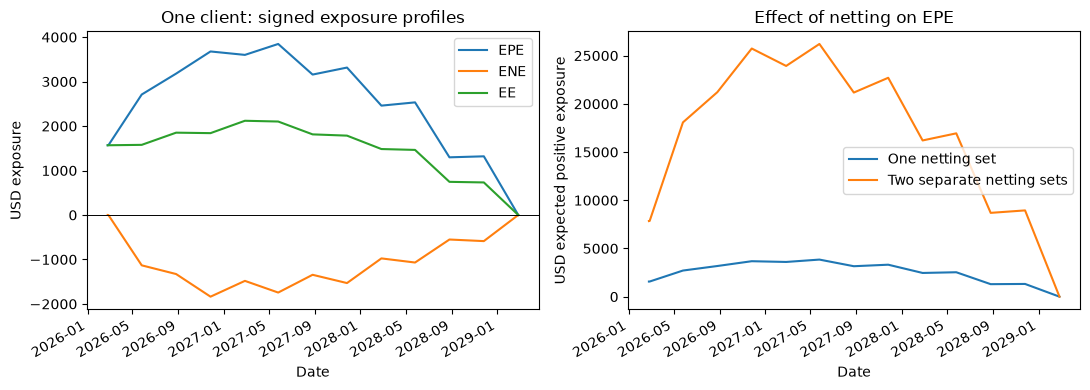

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
dates = pd.to_datetime(profile.index)
for measure in ["epe", "ene", "ee"]:
    axes[0].plot(dates, profile[measure], label=measure.upper())
axes[0].set(
    title="One client: signed exposure profiles", xlabel="Date", ylabel="USD exposure"
)
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].legend()
axes[1].plot(dates, profile["epe"], label="One netting set")
axes[1].plot(dates, separate_total["epe"], label="Two separate netting sets")
axes[1].set(
    title="Effect of netting on EPE",
    xlabel="Date",
    ylabel="USD expected positive exposure",
)
axes[1].legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


Combining the swaps within one set allows their values to offset before
taking the positive part. Separate agreements maintain separate exposure and
collateral balances.

The next table compares those groupings with variation margin enabled, then
runs the combined portfolio with margin disabled. Credit, funding and model
inputs stay fixed.


In [5]:
unmargined_csa = qs.CsaTerms(
    collateral_index=csa.collateral_index,
    collateral_currency=csa.collateral_currency,
    credit_index=csa.credit_index,
    credit_spread=csa.credit_spread,
    recovery=csa.recovery,
    funding_spread_curve=csa.funding_spread_curve,
    counterparty_threshold=csa.counterparty_threshold,
    own_threshold=csa.own_threshold,
    minimum_transfer_amount=csa.minimum_transfer_amount,
    variation_margin=False,
)
unmargined = run_exposure([qs.NettingSet("ONE-CLIENT", [receive, pay], unmargined_csa)])
comparison = pd.concat(
    {
        "one set, margin on": netted.xva_values.groupby("measure")["value"].sum(),
        "separate sets, margin on": separate.xva_values.groupby("measure")[
            "value"
        ].sum(),
        "one set, margin off": unmargined.xva_values.groupby("measure")["value"].sum(),
    },
    axis=1,
)
comparison


,"one set, margin on","separate sets, margin on","one set, margin off"
measure,,,
CVA,14.881481,24.877061,70.973216
FVA,3.382016,0.002221,20.978690


In [6]:
parameter_risk = netted.sensitivities.copy()


def risk_coordinate(parameter):
    if ".CVA.Cds_" in parameter:
        return "survival probability (not CDS spread)"
    if parameter.endswith(".CVA.recovery"):
        return "recovery fraction"
    if ".FVA.funding_spread." in parameter:
        return "annual decimal funding spread"
    return "market quote (native units)"


parameter_risk["risk_coordinate"] = parameter_risk["parameter"].map(risk_coordinate)
parameter_risk.sort_values(
    "value", key=lambda series: series.abs(), ascending=False
).head(12)


,parameter,value,risk_coordinate
10,OIS_USD_SOFR_3Y,-1748.458502,market quote (native units)
8,OIS_USD_SOFR_2Y,799.522623,market quote (native units)
18,ONE-CLIENT.FVA.funding_spread.2027-02-24,358.412973,annual decimal funding spread
14,ONE-CLIENT.CVA.Cds_CORPORATE-A_USD_3Y,-282.778423,survival probability (not CDS spread)
19,ONE-CLIENT.FVA.funding_spread.2029-02-24,200.514583,annual decimal funding spread
7,OIS_USD_SOFR_1Y,135.146673,market quote (native units)
17,ONE-CLIENT.FVA.funding_spread.2026-02-24,96.715785,annual decimal funding spread
13,ONE-CLIENT.CVA.Cds_CORPORATE-A_USD_1Y,-62.036962,survival probability (not CDS spread)
16,ONE-CLIENT.CVA.recovery,-24.802469,recovery fraction
2,CapletFloorlet_USD_SOFR_3M_3M_Absolute_0.035_S...,-8.957471,market quote (native units)


## Adjustment formulas and reconciliation

For raw netting-set value $V_{p,i}$,

$$EPE_i=E[\max(V_{p,i},0)],\quad
ENE_i=E[\min(V_{p,i},0)],\quad EE_i=EPE_i+ENE_i.$$

Let $\widetilde V$ be the value after variation margin. The implemented
independent-credit approximation uses

$$CVA=(1-R)\sum_iD_iE[\max(\widetilde V_i,0)]
[S(t_{i-1})-S(t_i)],$$
$$FVA=\sum_iD_iE[\widetilde V_i]s_i\Delta t_i.$$

FVA integrates signed exposure at right endpoints with Actual/365 intervals.
CVA is reported as a positive loss measure; an application specifies its
accounting sign relative to clean PV. This high-level run returns CVA and FVA.

Netting reduces the sum of raw positive parts pathwise. Signed FVA can respond
differently, especially when separate collateral accounts change funding
needs. The experiment excludes wrong-way risk and stochastic credit dynamics.
We check profile identities, the netting inequality and the effect of margin
below.


In [7]:
print(
    f"Maximum raw EPE: netted USD {profile['epe'].max():,.2f}; separate USD {separate_total['epe'].max():,.2f}."
)
print(
    f"Netted CVA: margin on USD {comparison.loc['CVA', 'one set, margin on']:.4f}; off USD {comparison.loc['CVA', 'one set, margin off']:.4f}."
)
print(
    "Raw profiles are unchanged by margin; the adjustment changes because it uses post-margin paths."
)
comparison


Maximum raw EPE: netted USD 3,846.20; separate USD 26,207.85.
Netted CVA: margin on USD 14.8815; off USD 70.9732.
Raw profiles are unchanged by margin; the adjustment changes because it uses post-margin paths.


,"one set, margin on","separate sets, margin on","one set, margin off"
measure,,,
CVA,14.881481,24.877061,70.973216
FVA,3.382016,0.002221,20.978690


The comparison separates two effects: offsets reduce raw positive exposure,
while variation margin changes the residual exposure supplied to the
adjustment calculation. Signed funding contributions can cancel, so EPE alone
is insufficient to explain FVA.


Increase path count, refine the exposure grid and compare seeds to assess
numerical stability. These results depend on the selected one-currency model,
calibration basket and agreement inputs.
